# Очередь заявок на кейтеринг

При рабочем лимите 225 заявок сортировка модели охватила 88 из 99 исторических договоров. При одинаковом лимите 175 модель нашла 79, текущее правило — 55. Предлагаю испытать такой порядок обработки в пилоте.

## 1. Управленческий вопрос

Пять менеджеров могут подробно вести 30 % входящих заявок. Оценка нужна после первого ответа. Основная метрика отчёта — доля завершившихся договором заявок, попавших в очередь. Для отбора модели использую ROC-AUC на пяти фолдах. До первого ответа потребуется отдельный вариант без response_hours.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score
RANDOM_STATE=42
MODEL_SEED=0

In [2]:
d=pd.read_csv(Path("../data/catering_leads.csv"))
conv_rate=round(d.converted.mean(),3)
n_contracts=d.converted.sum()
budget_na=round(d.budget_pp.isna().mean(),3)
size_na=d.company_size.isna().sum()
contract_match=(d.contract_rub.notna()==(d.converted==1)).all()
assert d.lead_id.is_unique
print(len(d),n_contracts,conv_rate,budget_na,size_na,contract_match)

3000 398 0.133 0.262 243 True


В 3 000 заявках 398 договоров (13,3 %). Бюджет пропущен в 26,2 % заявок, размер компании в 243. Сумма договора заполнена ровно у подписанных сделок, поэтому её исключил.

## 2. Клиенты, каналы и время

In [3]:
by_channel=d.groupby("channel").converted.mean().sort_values(ascending=False).round(3)
def rate(mask):
    return round(d.loc[mask,"converted"].mean(),3)
repeat_rate,new_rate=rate(d.repeat_client==1),rate(d.repeat_client==0)
fast_rate,slow_rate=rate(d.response_hours<=1),rate(d.response_hours>8)
print(by_channel,repeat_rate,new_rate,fast_rate,slow_rate)

channel
рекомендация    0.364
звонок          0.177
выставка        0.100
сайт            0.092
соцсети         0.048
тендер          0.038
Name: converted, dtype: float64 0.389 0.087 0.233 0.03


In [4]:
def rate(mask):
    return round(d.loc[mask,"converted"].mean(),3)
size_na_rate,size_ok_rate=rate(d.company_size.isna()),rate(d.company_size.notna())
budget_na_rate,budget_ok_rate=rate(d.budget_pp.isna()),rate(d.budget_pp.notna())
budget_high,budget_low=rate(d.budget_pp>=450),rate(d.budget_pp<450)
print(size_na_rate,size_ok_rate,budget_na_rate,budget_ok_rate,budget_high,budget_low)

0.086 0.137 0.12 0.137 0.174 0.058


In [5]:
created=pd.to_datetime(d.created)
d["hour"]=created.dt.hour
d["weekday"]=created.dt.dayofweek
d["evening"]=(d.hour>=19).astype(int)
e=d.evening==1
evening_share=round(e.mean(),3)
evening_rate,day_rate=round(d.converted[e].mean(),3),round(d.converted[~e].mean(),3)
evening_wait,day_wait=round(d.response_hours[e].median(),1),round(d.response_hours[~e].median(),1)
print(evening_share,evening_rate,day_rate,evening_wait,day_wait)

0.112 0.024 0.146 13.2 2.1


По рекомендациям договорами заканчиваются 36,4 % заявок, у повторных клиентов — 38,9 %. При ответе до часа конверсия 23,3 %, при ожидании свыше восьми часов — 3,0 %. Вечерние заявки ждут первого ответа дольше: медиана 13,2 часа против 2,1 днём. Источники и качество заявок могут различаться.

## 3. Модели и подбор настроек

In [6]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
num = ["guests", "budget_pp", "days_to_event", "response_hours", "repeat_client", "tasting",
       "hour", "weekday", "evening"]
cat = ["channel", "event_type", "city", "company_size", "manager"]
y=d.converted
X=d.drop(columns=["lead_id","created","converted","contract_rub"])
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=RANDOM_STATE,stratify=y)
pre=ColumnTransformer([("num",make_pipeline(SimpleImputer(strategy="median"),StandardScaler()),num),("cat",make_pipeline(SimpleImputer(strategy="constant",fill_value="не указан"),OneHotEncoder(handle_unknown="ignore")),cat)])
pipe=Pipeline([("prep",pre),("model",LogisticRegression(max_iter=2000))])
n_features=pre.fit_transform(X_train).shape[1]
cv_auc=round(cross_val_score(pipe,X_train,y_train,cv=kf,scoring="roc_auc").mean(),3)
print(n_features,cv_auc)
print([int(y_train.iloc[va].sum()) for _,va in kf.split(X_train)])

36 0.859
[61, 55, 69, 54, 60]


In [7]:
def score(m,s):
    return round(cross_val_score(m,X_train,y_train,cv=kf,scoring=s).mean(),3)
dummy_acc=score(DummyClassifier(strategy="most_frequent"),"accuracy")
def forest(weight=None):
    m=RandomForestClassifier(n_estimators=50,min_samples_leaf=5,random_state=MODEL_SEED,class_weight=weight)
    return Pipeline([("prep",pre),("model",m)])
forest_acc,forest_f1=score(forest(),"accuracy"),score(forest(),"f1")
balanced_f1=score(forest("balanced"),"f1")
print(dummy_acc,forest_acc,forest_f1,balanced_f1)

0.867 0.878 0.195 0.536


In [8]:
def catch_rate(y_true,scores,share=.3):
    k=int(share*len(y_true))
    idx=pd.Series(scores,index=y_true.index).nlargest(k).index
    return y_true.loc[idx].sum()/y_true.sum()
r=(X_train.repeat_client==1)|(X_train.channel=="рекомендация")
rule_share,rule_catch=round(r.mean(),3),round(y_train[r].sum()/y_train.sum(),3)
random_catch=round(catch_rate(y_train,np.random.default_rng(0).random(len(y_train))),3)
print(rule_share,rule_catch,random_catch)

0.223 0.579 0.314


In [9]:
grid=GridSearchCV(pipe,{"model__C":[.01,.1,1,10],"model__class_weight":[None,"balanced"]},cv=kf,scoring="roc_auc").fit(X_train,y_train)
best_params,best_auc=grid.best_params_,round(grid.best_score_,3)
res=pd.DataFrame(grid.cv_results_)
spread=round(res.mean_test_score.max()-res.mean_test_score.min(),3)
print(best_params,best_auc,spread)
res[["params","mean_test_score","std_test_score"]].sort_values("mean_test_score",ascending=False)

{'model__C': 1, 'model__class_weight': None} 0.859 0.015


,params,mean_test_score,std_test_score
4,"{'model__C': 1, 'model__class_weight': None}",0.859155,0.016676
2,"{'model__C': 0.1, 'model__class_weight': None}",0.857996,0.013436
6,"{'model__C': 10, 'model__class_weight': None}",0.857987,0.018049
3,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.856725,0.013563
5,"{'model__C': 1, 'model__class_weight': 'balanc...",0.855527,0.016379
7,"{'model__C': 10, 'model__class_weight': 'balan...",0.854845,0.017053
1,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.847598,0.017654
0,"{'model__C': 0.01, 'model__class_weight': None}",0.843954,0.015597


Подготовка дала 36 признаков. На CV постоянный прогноз получил accuracy 86,7 %. У обычного леса accuracy 87,8 %, но F1 для договоров 0,195. С весами классов F1 поднялся до 0,536. Для приоритизации выбрал логистическую модель по ROC-AUC: лучшее значение 0,859 при C=1 и обычных весах. Разброс средних AUC по всей сетке 0,015.

## 4. Очередь при равных ограничениях

0.909 0.889 0.233 0.556 0.798


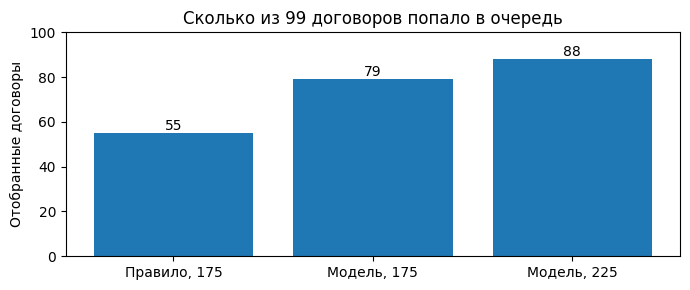

In [10]:
best=grid.best_estimator_
p=best.predict_proba(X_test)[:,1]
test_auc=round(roc_auc_score(y_test,p),3)
model_catch=round(catch_rate(y_test,p),3)
r=(X_test.repeat_client==1)|(X_test.channel=="рекомендация")
rule_share_test,rule_catch_test=round(r.mean(),3),round(y_test[r].sum()/y_test.sum(),3)
model_same=round(catch_rate(y_test,p,share=r.mean()),3)
rank=pd.Series(p,index=X_test.index)
k=int(.3*len(rank))
ix=rank.nlargest(k).index
priority=d.loc[ix,["lead_id"]].assign(score=rank.loc[ix])
priority.to_csv("../priority.csv",index=False)
print(test_auc,model_catch,rule_share_test,rule_catch_test,model_same)
v=[int(y_test[r].sum()),int(y_test.loc[rank.nlargest(int(r.sum())).index].sum()),int(y_test.loc[ix].sum())]
fig,ax=plt.subplots(figsize=(7,3))
bars=ax.bar(["Правило, 175","Модель, 175","Модель, 225"],v)
ax.bar_label(bars)
ax.set(ylabel="Отобранные договоры",title="Сколько из 99 договоров попало в очередь",ylim=(0,100))
fig.tight_layout()
plt.show()

ROC-AUC на тесте — 0,909. При 225 местах модель нашла 88 договоров, случайный список такого размера нашёл бы в среднем около 30. Правило выбрало 175 заявок, из них 55 завершились договором. При 175 местах в модели — 79, преимущество в историческом списке составляет 24 договора.

## 5. Выводы и рекомендации

In [11]:
num_now=[c for c in num if c!="response_hours"]
pnow=ColumnTransformer([("num",make_pipeline(SimpleImputer(strategy="median"),StandardScaler()),num_now),("cat",make_pipeline(SimpleImputer(strategy="constant",fill_value="не указан"),OneHotEncoder(handle_unknown="ignore")),cat)])
m=Pipeline([("prep",pnow),("model",LogisticRegression(max_iter=2000))]).fit(X_train,y_train)
catch_now=round(catch_rate(y_test,m.predict_proba(X_test)[:,1]),3)
oleg=d.manager=="Олег"
oleg_wait,others_wait=round(d.response_hours[oleg].median(),1),round(d.response_hours[~oleg].median(),1)
fast=d.response_hours<=2
oleg_fast,others_fast=round(d.converted[oleg&fast].mean(),3),round(d.converted[~oleg&fast].mean(),3)
print(catch_now,oleg_wait,others_wait,oleg_fast,others_fast)

0.848 5.9 2.1 0.215 0.197


In [12]:
joblib.dump(best,"../catering.joblib")
restored=joblib.load("../catering.joblib")
print(np.allclose(restored.predict_proba(X_test)[:,1],p))

True


Вариант без времени ответа охватил 84,8 % договоров. Медиана ожидания у Олега 5,9 часа, у остальных 2,1 часа. При ответе в пределах двух часов у Олега конверсия 21,5 %, у остальных 19,7 %. Эти сравнения не позволяют приписать выигрыш ускорению ответа. Для оценки очереди в работе предложил бы случайно назначать правило или модель сопоставимым группам заявок при одном бюджете и измерять дополнительные договоры. Отдельно стоит проверить результат на новом календарном периоде.